# General homodyne scans

Plotting and data handling are from `homodyne_scan_plotting.py`.
Check the file is in `src/monitored_cluster_states/` of the repository used by this kernel.
Run the imports first; each following section then runs independently.


In [33]:
from monitored_cluster_states.paths import DATA_DIR, FIGURES_DIR
import monitored_cluster_states.homodyne_scan_plotting as plotting
import importlib
import matplotlib.pyplot as plt

plotting = importlib.reload(plotting)
SAVE_PDF = True
OUTPUT_DIR = FIGURES_DIR / "homodyne_scan" if SAVE_PDF else None


## 1. Entropy density: angles and tolerances

At one size, compare angles at fixed tolerance (left) and tolerances at fixed angle (right). Bands show one SEM from stored realisations/statistics.


In [34]:
SCAN_DIR = DATA_DIR / "homodyne_general" / "Scanning_phi_tolerance"
R_FIXED, W_FIXED = 1.0, 1.0
TARGET_L = 60
FIXED_PHI = 1e-6
FIXED_TOLERANCE = 1e-6
SHOW_SEM = True
FILE_SETTINGS = {}  # Optional metadata overrides keyed by relative filename.

scan = plotting.load_homodyne_scan(
    SCAN_DIR, r=R_FIXED, weight=W_FIXED, file_settings=FILE_SETTINGS,
)


Available angles (radians): [0.0, 1e-08, 1e-07, 1e-06, 1e-05]
Available tolerances: [0.0, 1e-06, 1e-05, 0.0001, 0.001]


Both panels: L=60; left tolerance=1e-06; right phi=1e-06 rad


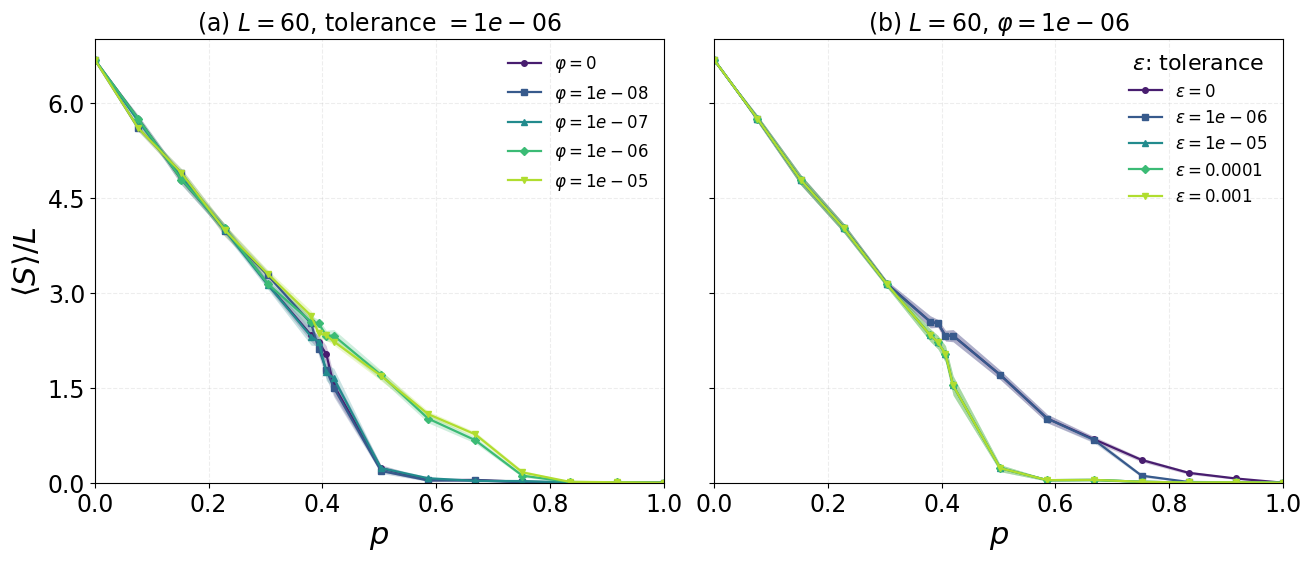

Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\results\figures\homodyne_scan\homodyne_phi_tolerance_L_60_phi_1e-06_tol_1e-06.pdf


In [35]:
comparison = plotting.plot_homodyne_phi_tolerance(
    scan, OUTPUT_DIR, target_L=TARGET_L,
    fixed_phi=FIXED_PHI, fixed_tolerance=FIXED_TOLERANCE,
    show_sem=SHOW_SEM,
)
plt.show()
print("Saved:", comparison["path"])


## 2. Compare weights and squeezing

Columns: weight. Rows: squeezing. All panels share a colour scale.
Grey cells indicate missing or undefined ratios, including unfinished scans.

The colour is $R=(\langle S(L_\mathrm{large})\rangle/L_\mathrm{large})/
(\langle S(L_\mathrm{small})\rangle/L_\mathrm{small})$.

In [36]:
BASE_DIR = DATA_DIR / "homodyne_general" / "Scanning_phi_tolerance_SCAN_w_r"
W_VALUES = [0.5, 1.0, 2.0]
R_VALUES = [0.5, 1.0, 2.0] 
P_TARGET = 0.6
L_SMALL, L_LARGE = 30, 60


Not available yet: w=0.5, r=0.5
Available angles (radians): [0.0, 1e-12, 1.584893192461111e-12, 2.5118864315095823e-12, 3.9810717055349695e-12, 6.309573444801943e-12, 1e-11, 1.5848931924611107e-11, 2.5118864315095823e-11, 3.9810717055349695e-11, 6.309573444801942e-11, 1e-10, 1.584893192461111e-10, 2.511886431509582e-10, 3.9810717055349694e-10, 6.309573444801942e-10, 1e-09, 1.584893192461111e-09, 2.511886431509582e-09, 3.981071705534969e-09, 6.309573444801943e-09, 1e-08, 1.5848931924611143e-08, 2.511886431509582e-08, 3.9810717055349776e-08, 6.309573444801943e-08, 1e-07]
Available tolerances: [0.0, 1e-12, 1.584893192461111e-12, 2.5118864315095823e-12, 3.9810717055349695e-12, 6.309573444801943e-12, 1e-11, 1.5848931924611107e-11, 2.5118864315095823e-11, 3.9810717055349695e-11, 6.309573444801942e-11, 1e-10, 1.584893192461111e-10, 2.511886431509582e-10, 3.9810717055349694e-10, 6.309573444801942e-10, 1e-09, 1.584893192461111e-09, 2.511886431509582e-09, 3.981071705534969e-09, 6.309573444801943

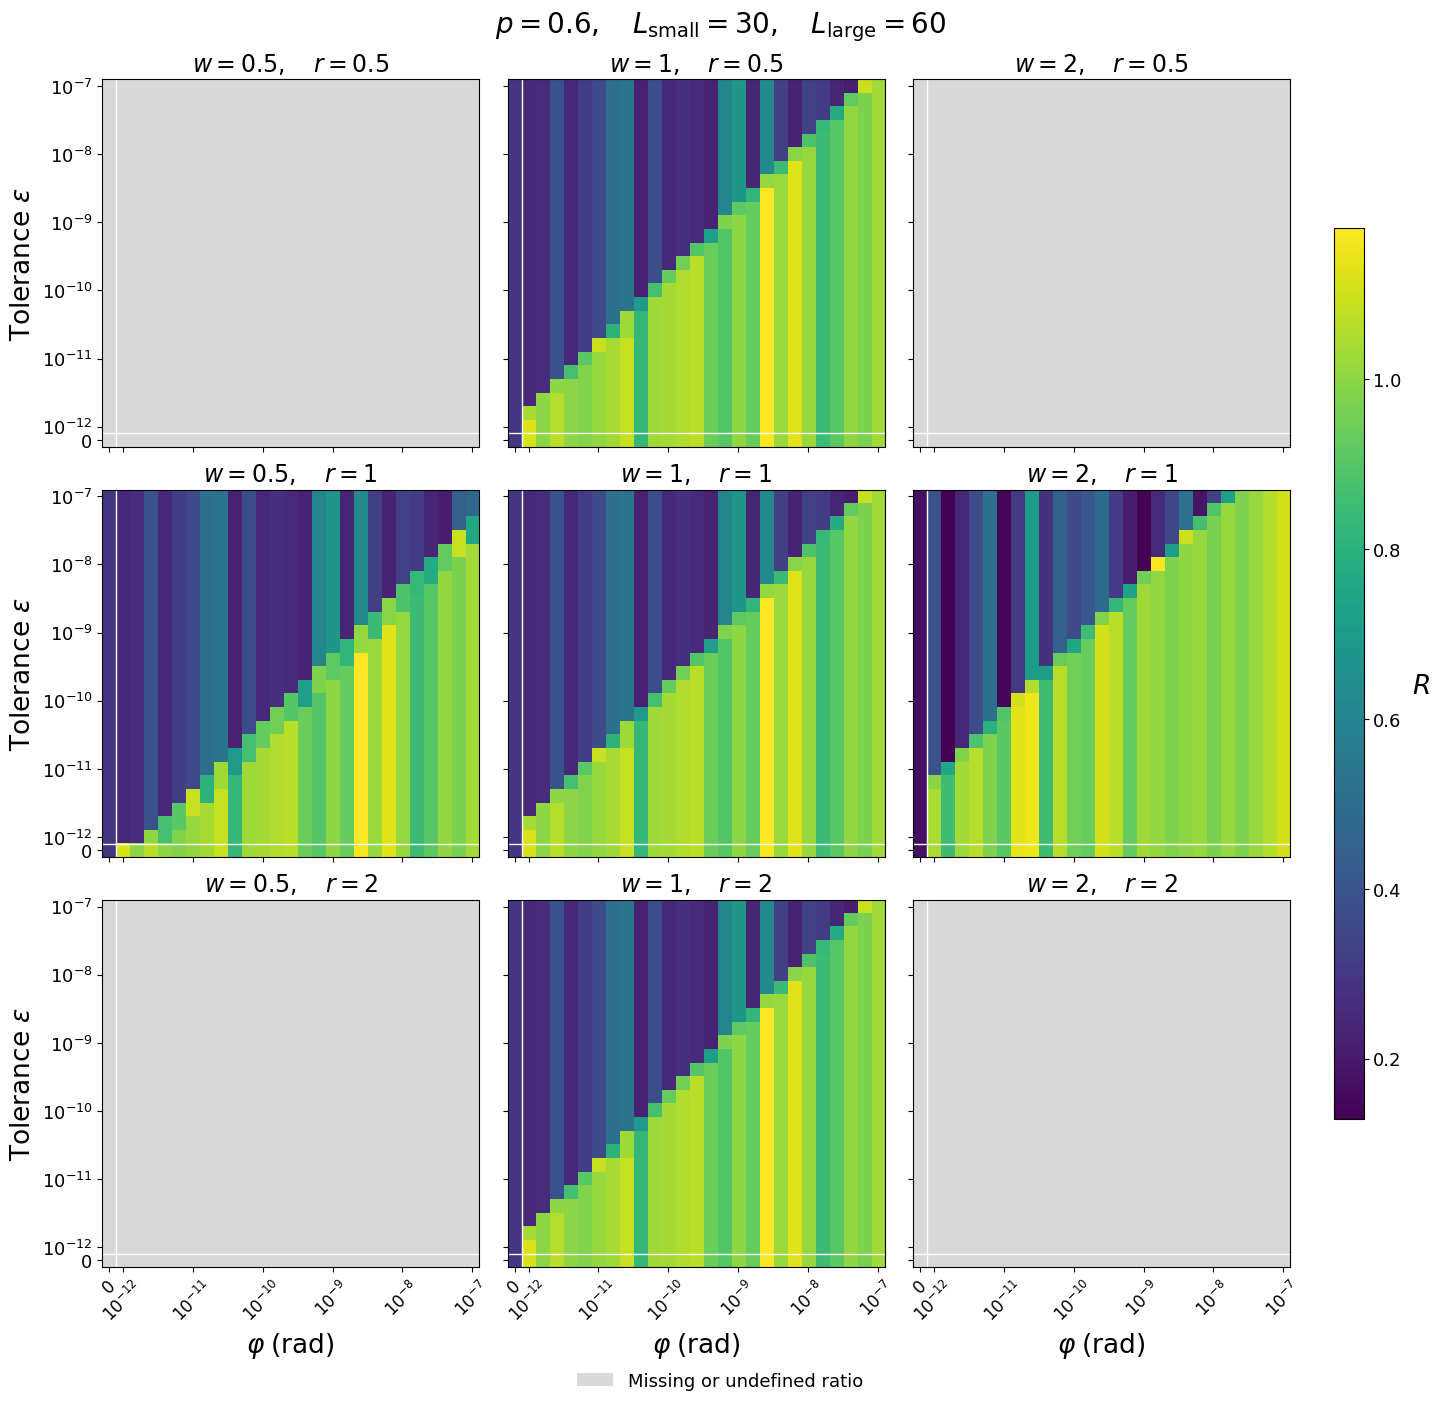

Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\results\figures\homodyne_scan\heatmaps_p_0.6_w_0.5_1_2_r_0.5_1_2_L_30_60.pdf


In [37]:
heatmap_comparison = plotting.plot_homodyne_scan_heatmaps(
    BASE_DIR, OUTPUT_DIR, weights=W_VALUES, squeezings=R_VALUES,
    p_target=P_TARGET, L_small=L_SMALL, L_large=L_LARGE,
)
plt.show()
print("Saved:", heatmap_comparison["path"])


## 3. Single heatmap

Load a single scan folder. This section calculates its own ratio, so it does not
reuse data from the comparison above. All available angle/tolerance values are used.


In [38]:
SINGLE_DIR = DATA_DIR / "homodyne_general" / "Scanning_phi_tolerance_P_06_fixed"
SINGLE_W, SINGLE_R = 1.0, 1.0
SINGLE_P = 0.6
SINGLE_L_SMALL, SINGLE_L_LARGE = 30, 60

single_scan = plotting.load_homodyne_scan(
    SINGLE_DIR, r=SINGLE_R, weight=SINGLE_W, file_settings={},
)


Available angles (radians): [0.0, 1e-08, 2.1544346900318822e-08, 4.641588833612782e-08, 1e-07, 2.1544346900318822e-07, 4.6415888336127725e-07, 1e-06, 2.1544346900318822e-06, 4.641588833612773e-06, 1e-05]
Available tolerances: [0.0, 1e-08, 2.1544346900318822e-08, 4.641588833612782e-08, 1e-07, 2.1544346900318822e-07, 4.6415888336127725e-07, 1e-06, 2.1544346900318822e-06, 4.641588833612773e-06, 1e-05]


w=1, r=1: 121/121 cells available
Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\results\figures\homodyne_scan\heatmaps_p_0.6_w_1_r_1_L_30_60.pdf


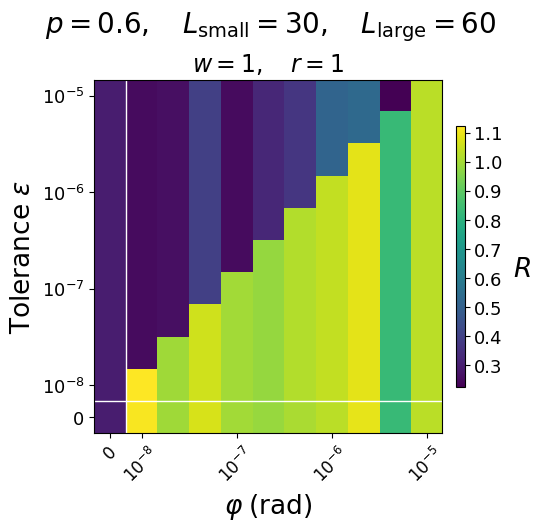

Saved: C:\Users\Mireia\Desktop\Master\ICFO\TFM\monitored-cluster-state-simulations\results\figures\homodyne_scan\heatmaps_p_0.6_w_1_r_1_L_30_60.pdf


In [39]:
single_heatmap = plotting.plot_homodyne_scaling_ratio(
    single_scan, OUTPUT_DIR, p_target=SINGLE_P,
    L_small=SINGLE_L_SMALL, L_large=SINGLE_L_LARGE,
)
plt.show()
print("Saved:", single_heatmap["path"])
